[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/danpele/Blockchain-Applications/blob/main/Quantlets/L3/BA_L3_es_scatter/BA_L3_es_scatter.ipynb)

# BA_L3_es_scatter: Realised loss against predicted ES on tail days

*Quantlet of Lecture 3, Blockchain Applications. Daniel Traian Pele, Bucharest University of Economic Studies.*

Bitcoin, 1 January 2020 to 18 September 2026: on each day beyond the forecast 2.5% quantile, the realised loss against the ES 2.5% predicted the day before, for the Normal VaR on 250 days and for GARCH(1,1)-t; mean and median ratio of loss to predicted ES.

In [1]:
# packages that are not preinstalled on Colab
import importlib, subprocess, sys
for pkg in ['arch']:
    try:
        importlib.import_module(pkg)
    except ImportError:
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', pkg], check=True)

In [2]:
OUT_DIR = '.'
SAVE_TO_DRIVE = False

In [3]:
import os
import tempfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings('ignore')
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)

# Chart style: transparent background, legend below the plot, no grey
plt.rcParams.update({
    'figure.facecolor': 'none', 'axes.facecolor': 'none', 'savefig.facecolor': 'none', 'savefig.transparent': True,
    'axes.grid': False, 'font.size': 11, 'axes.labelsize': 12, 'axes.titlesize': 12,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.linewidth': 0.6, 'lines.linewidth': 1.3,
    'legend.facecolor': 'none', 'legend.framealpha': 0, 'legend.fontsize': 10,
})

# Chart colours (the same as in the slides)
BTC, ETH, BLUE, GOLD, RED, GREEN = '#E8913A', '#9B59B6', '#1A3A6E', '#B5853F', '#CD0000', '#2E7D32'
ORANGE, PURPLE, NAVY, TEAL = '#E67E22', '#8E44AD', '#1F2A44', '#17A2B8'

# outputs go to OUT_DIR (Google Drive) if SAVE_TO_DRIVE = True, otherwise to a temporary folder
OUT_PATH = OUT_DIR if globals().get('SAVE_TO_DRIVE') else tempfile.gettempdir()


def save_fig(fig, name):
    """Save the figure as PDF and PNG in OUT_PATH, then show it."""
    fig.savefig(os.path.join(OUT_PATH, f'{name}.pdf'), bbox_inches='tight')
    fig.savefig(os.path.join(OUT_PATH, f'{name}.png'), bbox_inches='tight', dpi=150)
    plt.show()
    plt.close(fig)


def legend_below(fig, ncol=3, bottom=0.08):
    """One legend for the whole figure, outside the plot, bottom centre (bottom = share of the height kept for it)."""
    h, l = [], []
    for ax in fig.axes:
        hh, ll = ax.get_legend_handles_labels()
        h += hh; l += ll
    fig.legend(h, l, loc='lower center', ncol=ncol, frameon=False)
    fig.tight_layout(rect=(0, bottom, 1, 1))

In [4]:
# Course data: the local copy if the notebook runs inside the repository, otherwise GitHub
REPO_RAW = 'https://raw.githubusercontent.com/danpele/Blockchain-Applications/main/data/'
DATA_DIR = next((os.path.join(d, 'data') for d in ('.', '..', '../..', '../../..') if os.path.isdir(os.path.join(d, 'data', 'market'))), '')


def data_file(sub, name):
    """Path or URL of data/<sub>/<name>."""
    return os.path.join(DATA_DIR, sub, name) if DATA_DIR else REPO_RAW + f'{sub}/{name}'


def daily(sym, end=None):
    """Daily closes from EODHD (data/market/<sym>.csv), positive prices only."""
    p = pd.read_csv(data_file('market', f'{sym}.csv'), parse_dates=['date']).set_index('date')['close']
    p = p[p > 0]
    return p.loc[:end] if end else p


def hourly(sym):
    """Hourly closes from EODHD (data/hourly/<sym>_1h.csv), indexed by UTC time."""
    x = pd.read_csv(data_file('hourly', f'{sym}_1h.csv'))
    x.index = pd.to_datetime(x['timestamp'], unit='s')
    return x['close']


def onchain(name):
    """Daily on-chain series (data/onchain/Crypto_<name>_20251008.csv), one column per coin."""
    return pd.read_csv(data_file('onchain', f'Crypto_{name}_20251008.csv'), na_values='NA', parse_dates=['date']).set_index('date')

**Data.** Bitcoin daily log returns in per cent (EODHD); the windows use returns from 2015, the test period is 1 January 2020 – 18 September 2026.

**Method.** For each day $t$, using data up to $t-1$: the 2.5% quantile and the ES 2.5% of the Normal on the last 250 days, and of GARCH(1,1)-t re-estimated every 21 days and filtered daily.
A tail day is a day with $r_t$ below the forecast 2.5% quantile; the ratio of realised loss $-r_t$ to predicted ES is 1 on average for a correct ES (McNeil and Frey, 2000).

**How to read.** One dot per tail day; dashed line: realised loss = predicted ES. Losses above 19% are drawn at 19% with a triangle and labelled.

In [5]:
from scipy import stats
from arch import arch_model

END = '2026-09-18'                      # last day of the estimation sample
ASSETS = {'Bitcoin': ('BTC-USD.CC', 365, BTC), 'Ethereum': ('ETH-USD.CC', 365, ETH),
          'S&P 500': ('GSPC.INDX', 252, BLUE), 'Gold': ('XAUUSD.FOREX', 252, GOLD)}


def closes(sym, end):
    # daily closes; S&P 500 and gold: Monday-Friday only, repeated closes removed
    p = daily(sym, end)
    if sym.endswith(('.INDX', '.FOREX')):
        p = p[p.index.dayofweek < 5]
        p = p[p.diff().ne(0)]
    return p


def log_returns(sym, start='2018-01-01'):
    # daily log returns in %, from `start` to END
    p = closes(sym, END)
    return (100 * np.log(p).diff()).dropna().loc[start:]

In [6]:
lam = 0.94     # RiskMetrics decay


def ewma_forecasts(r, lam=lam):
    # one-step EWMA variance forecasts: value at t = forecast for day t made at the end of day t-1;
    # started at the variance of the first 250 days; the last element is the forecast for the day after the sample
    v = r.iloc[:250].var(); out = []
    for x in r.values:
        out.append(v)
        v = lam * v + (1 - lam) * x ** 2
    return pd.Series(out, index=r.index), v

p1, p25 = 0.01, 0.025
z1, z25 = stats.norm.ppf(p1), stats.norm.ppf(p25)


def es_factor(q, p, nu):
    # f_nu(q) / p * (nu + q^2) / (nu - 1): the ES multiplier of the standard Student-t
    return stats.t.pdf(q, nu) / p * (nu + q ** 2) / (nu - 1)

In [7]:
full = (100 * np.log(daily('BTC-USD.CC', END)).diff()).dropna().loc['2015-01-01':]
test = full.loc['2020-01-01':]
idx = test.index
loc = {t_: i for i, t_ in enumerate(full.index)}
q25f = {m_: pd.Series(np.nan, index=idx) for m_ in ['Normal 250', 'GARCH-t']}       # minus the 2.5% quantile
pred_es = {m_: pd.Series(np.nan, index=idx) for m_ in ['Normal 250', 'GARCH-t']}    # ES 2.5%
for t_ in idx:
    w250 = full.iloc[loc[t_] - 250:loc[t_]]
    q25f['Normal 250'][t_] = -(w250.mean() + w250.std() * z25)
    pred_es['Normal 250'][t_] = -w250.mean() + w250.std() * stats.norm.pdf(z25) / p25
for b0 in range(0, len(idx), 21):
    t0 = idx[b0]; hist = full.iloc[:loc[t0]]
    prm = arch_model(hist, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fit(disp='off').params
    seg = full.iloc[:loc[idx[min(b0 + 20, len(idx) - 1)]] + 1]
    fc = arch_model(seg, mean='Constant', vol='GARCH', p=1, q=1, dist='t').fix(prm).forecast(horizon=1, start=hist.index[-1], reindex=False)
    nu_b = prm['nu']; sc_b = np.sqrt((nu_b - 2) / nu_b); q = stats.t.ppf(p25, nu_b)
    for orig, vv in fc.variance.iloc[:, 0].items():
        j_ = loc[orig] + 1
        if j_ >= len(full) or full.index[j_] < t0:
            continue
        tday, sd = full.index[j_], np.sqrt(vv)
        q25f['GARCH-t'][tday] = -(prm['mu'] + sd * sc_b * q)
        pred_es['GARCH-t'][tday] = -prm['mu'] + sd * sc_b * es_factor(q, p25, nu_b)

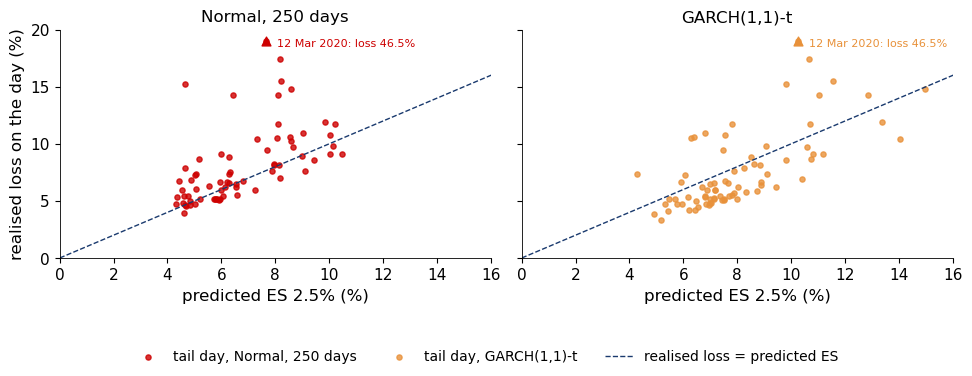

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True, sharey=True)
sc_rows = {}
for a_x, m_, cl_, lab_ in [(ax[0], 'Normal 250', RED, 'Normal, 250 days'), (ax[1], 'GARCH-t', BTC, 'GARCH(1,1)-t')]:
    hit = test < -q25f[m_]
    loss, esp = -test[hit], pred_es[m_][hit]
    cap = 19.0; big = loss > cap
    a_x.scatter(esp, np.minimum(loss, cap), s=14, color=cl_, alpha=0.8, label=f'tail day, {lab_}')
    a_x.scatter(esp[big], np.full(big.sum(), cap), s=40, marker='^', color=cl_)
    for d_ in loss.index[big]:
        a_x.annotate(f'{d_:%d %b %Y}: loss {loss[d_]:.1f}%', (esp[d_], cap), xytext=(8, -4), textcoords='offset points', fontsize=8, color=cl_)
    a_x.plot([0, 20], [0, 20], color=BLUE, lw=1, ls='--', label=('realised loss = predicted ES' if m_ == 'GARCH-t' else None))
    a_x.set_xlim(0, 16); a_x.set_ylim(0, 20); a_x.set_xlabel('predicted ES 2.5% (%)'); a_x.set_title(lab_)
    sc_rows[m_] = {'tail days': int(hit.sum()), 'above the line': int((loss > esp).sum()), 'share above (%)': 100 * (loss > esp).mean(),
                   'mean ratio R bar': (loss / esp).mean(), 'median ratio': (loss / esp).median(),
                   'predicted ES on 12 Mar 2020 (%)': esp.get(pd.Timestamp('2020-03-12'))}
ax[0].set_ylabel('realised loss on the day (%)')
legend_below(fig, ncol=3); fig.tight_layout(rect=(0, 0.14, 1, 1))
save_fig(fig, 'ba_l3_es_scatter')

**Key numbers** (as on the slide).

In [9]:
pd.DataFrame(sc_rows).T.round(2)

,tail days,above the line,share above (%),mean ratio R bar,median ratio,predicted ES on 12 Mar 2020 (%)
Normal 250,71.0,43.0,60.56,1.26,1.07,7.67
GARCH-t,76.0,18.0,23.68,0.97,0.83,10.25
